In [1]:

from pathlib import Path
from collections import Counter
from PIL import Image
import os

# Kaggle input location
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/ubiris_v2_project")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("UBIRIS V2 — NOTEBOOK 01: DATASET INSPECTION")
print("=" * 65)

inputs = [p for p in INPUT_ROOT.iterdir()] if INPUT_ROOT.exists() else []
print("\nKaggle inputs:")
for p in inputs:
    print(" -", p.name, "| directory:", p.is_dir())

# Inspect directories and file counts without opening every image
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
file_counts = Counter()
sample_paths = []
total_files = 0

for root, dirs, files_in_dir in os.walk(INPUT_ROOT):
    dirs[:] = [d for d in dirs if not d.startswith(".")]
    total_files += len(files_in_dir)

    for filename in files_in_dir:
        path = Path(root) / filename
        ext = path.suffix.lower()
        file_counts[ext or "[no extension]"] += 1

        if ext in image_exts and len(sample_paths) < 30:
            sample_paths.append(path)

print(f"\nTotal files found: {total_files}")
print("\nFile extensions:")
for ext, count in file_counts.most_common(15):
    print(f" {ext}: {count}")

print("\nDirectory structure (first 35 directories):")
dir_count = 0
for root, dirs, files_in_dir in os.walk(INPUT_ROOT):
    dirs[:] = sorted(d for d in dirs if not d.startswith("."))
    if dir_count >= 35:
        break
    print(f"{root}  [files: {len(files_in_dir)}]")
    dir_count += 1

print(f"\nInspecting {len(sample_paths)} sample images:")
for path in sample_paths:
    try:
        with Image.open(path) as im:
            print(f"{im.size} | {im.mode} | {path}")
    except Exception as e:
        print("UNREADABLE |", path.name, "|", str(e)[:100])

print("\nInspection complete — no model training performed.")
print("Working output:", OUTPUT_ROOT)


UBIRIS V2 — NOTEBOOK 01: DATASET INSPECTION

Kaggle inputs:
 - datasets | directory: True

Total files found: 5800

File extensions:
 .tiff: 5799
 .db: 1

Directory structure (first 35 directories):
/kaggle/input  [files: 0]
/kaggle/input/datasets  [files: 0]
/kaggle/input/datasets/pranavsunilwagh  [files: 0]
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2  [files: 0]
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2/ubiris2_1  [files: 0]
/kaggle/input/datasets/pranavsunilwagh/ubiris-v2/ubiris2_1/CLASSES_400_300_Part1  [files: 5800]

Inspecting 30 sample images:
(400, 300) | RGB | /kaggle/input/datasets/pranavsunilwagh/ubiris-v2/ubiris2_1/CLASSES_400_300_Part1/C252_S1_I7.tiff
(400, 300) | RGB | /kaggle/input/datasets/pranavsunilwagh/ubiris-v2/ubiris2_1/CLASSES_400_300_Part1/C255_S2_I9.tiff
(400, 300) | RGB | /kaggle/input/datasets/pranavsunilwagh/ubiris-v2/ubiris2_1/CLASSES_400_300_Part1/C150_S1_I12.tiff
(400, 300) | RGB | /kaggle/input/datasets/pranavsunilwagh/ubiris-v2/ubiris2_1/CLAS

Checked 500/5799 images
Checked 1000/5799 images
Checked 1500/5799 images
Checked 2000/5799 images
Checked 2500/5799 images
Checked 3000/5799 images
Checked 3500/5799 images
Checked 4000/5799 images
Checked 4500/5799 images
Checked 5000/5799 images
Checked 5500/5799 images


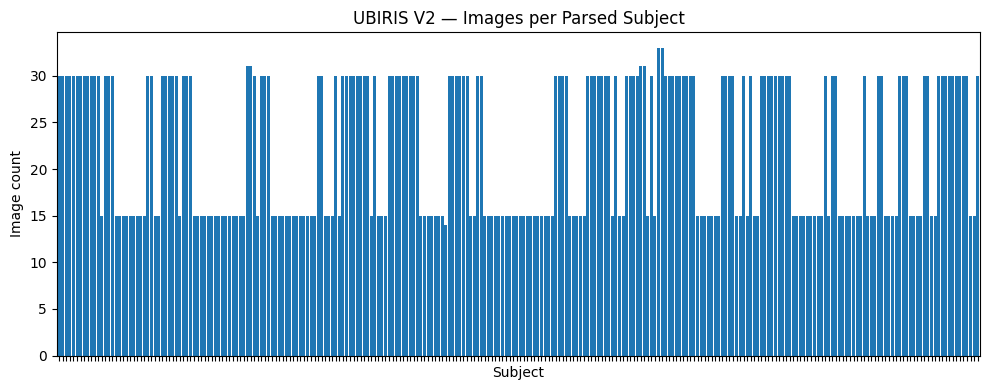


NOTEBOOK 01 — DATASET ANALYSIS COMPLETE
{
  "dataset": "UBIRIS V2",
  "dataset_directory": "/kaggle/input/datasets/pranavsunilwagh/ubiris-v2/ubiris2_1/CLASSES_400_300_Part1",
  "total_files_in_directory": 5800,
  "image_files_found": 5799,
  "readable_images": 5799,
  "unreadable_images": 0,
  "unique_parsed_subjects": 260,
  "filenames_matching_expected_pattern": 5799,
  "unique_sessions": 2,
  "image_dimensions": {
    "400x300": 5799
  },
  "image_modes": {
    "RGB": 5799
  },
  "exact_duplicate_images_after_decoding": 0,
  "filename_pattern": "C<subject>_S<session>_I<image>.tiff",
  "processing_seconds": 43.5
}

Saved files:
UBIRIS_V2_dataset_summary.json | 583 bytes
UBIRIS_V2_image_metadata.csv | 1,293,080 bytes
UBIRIS_V2_subject_distribution.png | 25,816 bytes
UBIRIS_V2_unreadable_images.csv | 1 bytes


In [2]:

from pathlib import Path
from collections import Counter
from PIL import Image, ImageFile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hashlib, json, re, time

ImageFile.LOAD_TRUNCATED_IMAGES = False

DATA_DIR = Path("/kaggle/input/datasets/pranavsunilwagh/ubiris-v2/ubiris2_1/CLASSES_400_300_Part1")
OUT_DIR = Path("/kaggle/working/ubiris_v2_project/notebook01_dataset_analysis")
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_DIR.is_dir(), f"Dataset directory not found: {DATA_DIR}"

files = sorted(p for p in DATA_DIR.iterdir() if p.is_file())
image_files = [p for p in files if p.suffix.lower() in {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}]

rows, errors, hashes = [], [], {}
start = time.time()

for i, path in enumerate(image_files, 1):
    match = re.match(r"^(C\d+)_S(\d+)_I(\d+)$", path.stem, re.I)
    subject = match.group(1).upper() if match else None
    session = int(match.group(2)) if match else None
    image_id = int(match.group(3)) if match else None

    try:
        with Image.open(path) as im:
            im.load()
            width, height = im.size
            mode = im.mode
            fmt = im.format

            # Hash decoded pixel content for exact duplicate detection
            pixel_hash = hashlib.sha256(
                str((im.size, im.mode)).encode() + im.tobytes()
            ).hexdigest()

        duplicate_of = hashes.get(pixel_hash)
        if duplicate_of is None:
            hashes[pixel_hash] = path.name

        rows.append({
            "filename": path.name,
            "path": str(path),
            "extension": path.suffix.lower(),
            "subject": subject,
            "session": session,
            "image_id": image_id,
            "width": width,
            "height": height,
            "mode": mode,
            "format": fmt,
            "file_size_bytes": path.stat().st_size,
            "readable": True,
            "pixel_sha256": pixel_hash,
            "duplicate_of": duplicate_of
        })
    except Exception as e:
        errors.append({"filename": path.name, "error": repr(e)})

    if i % 500 == 0:
        print(f"Checked {i}/{len(image_files)} images")

df = pd.DataFrame(rows)
err_df = pd.DataFrame(errors)

df.to_csv(OUT_DIR / "UBIRIS_V2_image_metadata.csv", index=False)
err_df.to_csv(OUT_DIR / "UBIRIS_V2_unreadable_images.csv", index=False)

valid_subjects = df["subject"].dropna() if not df.empty else pd.Series(dtype=str)
subject_counts = valid_subjects.value_counts()

summary = {
    "dataset": "UBIRIS V2",
    "dataset_directory": str(DATA_DIR),
    "total_files_in_directory": len(files),
    "image_files_found": len(image_files),
    "readable_images": len(df),
    "unreadable_images": len(errors),
    "unique_parsed_subjects": int(valid_subjects.nunique()),
    "filenames_matching_expected_pattern": int(valid_subjects.notna().sum()),
    "unique_sessions": int(df["session"].nunique()) if not df.empty else 0,
    "image_dimensions": {
        f"{w}x{h}": int(n)
        for (w, h), n in df.groupby(["width", "height"]).size().items()
    } if not df.empty else {},
    "image_modes": df["mode"].value_counts().to_dict() if not df.empty else {},
    "exact_duplicate_images_after_decoding": int(df["duplicate_of"].notna().sum()) if not df.empty else 0,
    "filename_pattern": "C<subject>_S<session>_I<image>.tiff",
    "processing_seconds": round(time.time() - start, 2)
}

with open(OUT_DIR / "UBIRIS_V2_dataset_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

if not subject_counts.empty:
    fig, ax = plt.subplots(figsize=(10, 4))
    subject_counts.sort_index().plot(kind="bar", ax=ax, width=0.85)
    ax.set_title("UBIRIS V2 — Images per Parsed Subject")
    ax.set_xlabel("Subject")
    ax.set_ylabel("Image count")
    ax.tick_params(axis="x", labelbottom=False)
    plt.tight_layout()
    fig.savefig(OUT_DIR / "UBIRIS_V2_subject_distribution.png", dpi=150)
    plt.show()
    plt.close(fig)

print("\n" + "=" * 60)
print("NOTEBOOK 01 — DATASET ANALYSIS COMPLETE")
print("=" * 60)
print(json.dumps(summary, indent=2))
print("\nSaved files:")
for p in sorted(OUT_DIR.iterdir()):
    print(f"{p.name} | {p.stat().st_size:,} bytes")



# Final Conclusion — UBIRIS V2 Dataset Collection and Analysis

## Dataset Overview
The UBIRIS V2 dataset input was inspected and analyzed successfully. The inspected directory contains 5,800 files, including 5,799 TIFF images and one additional database file.

## Key Findings
- Readable images: 5,799
- Unreadable images: 0
- Parsed subject identifiers: 260
- Distinct session identifiers: 2
- Image dimensions: 400 × 300 pixels
- Image mode: RGB
- Exact duplicate images detected by decoded pixel content: 0
- Filename pattern: `C<subject>_S<session>_I<image>.tiff`

## Generated Artifacts
The notebook generated an image metadata CSV, a dataset summary JSON, an unreadable-image report, and a subject-distribution plot.

## Limitations
Subject identifiers were extracted from filenames. These identifiers and their meaning should be confirmed against the dataset documentation before being treated as verified biometric identities. The duplicate check detects exact decoded-pixel matches, not visually similar images. The analysis covers the supplied `CLASSES_400_300_Part1` directory rather than every possible UBIRIS V2 release or subset.

## Conclusion
The inspected UBIRIS V2 image collection is readable and has consistent dimensions and RGB image mode. The generated metadata and summary provide a reproducible starting point for preprocessing and subsequent ocular recognition experiments. No model training was performed in this notebook.


In [3]:
import shutil
from pathlib import Path

folder = Path("/kaggle/working/ubiris_v2_project/notebook01_dataset_analysis")
zip_path = "/kaggle/working/UBIRIS_V2_Notebook01_Results.zip"

shutil.make_archive(zip_path.removesuffix(".zip"), "zip", folder)
print("ZIP created:", zip_path)

ZIP created: /kaggle/working/UBIRIS_V2_Notebook01_Results.zip
